# Project Description Phase 1

Consider the following (hypothetical) scenario: for the latest local election, an unnamed country decided to experiment with electoral technologies and to provide the possibility of casting a vote online for voters in a selected municipality. The rest of the voters voted on paper in their polling stations, as usual. The results of the election have shown that the votes cast electronically were distributed differently than the votes cast on paper. In order to investigate the possibility of election manipulation, as well as to study the demographics of voters who decided to cast their vote online, a survey was conducted (date of data collection 1/7/2025). For the sake of transparency, the statistical agency conducting the survey decided to release the results to the public. However, due to sensitive nature of the survey (in particular, the political preferences of the voters), the released dataset had to be anonymised beforehand.

In this project you will take the role of both the statistical agency (the anonymisers) and the adversary who attempts to learn the political preferences of the population from the released dataset (the deanonymisers). The project would therefore consist of two phases.

The submissions in both phases of the project will occur in groups, with only one submission per group. The submissions will be done using the Peer feedback activity.

Phase 1

You will receive the following files (in all the file names, X stands for the letter assigned to your group):

"private_dataX.xlsx" as the raw (i.e. non-anonymised) survey data,
"public_data_registerX.xlsx" as the public population register,
"public_data_resultsX.xlsx" as the published results of the election.
A description of the attributes in the datasets (same for all the groups) is furthermore available in the appendix at the bottom.

Your tasks during the first phase will be:

Step 1: Analyse the data in the raw dataset answering the following questions (note, you are free to choose the suitable methods of the analysis yourself, based on your knowledge of e.g. applied statistics or other courses of your study):

(A) Is there a significant difference between the political preferences as expressed in the survey and the election results for both electronic and polling station votes?

(B) Is there a significant difference between political preferences of the voters depending on their demographic attributes recorded in the survey (that is, age, gender, education level…)?

(C) Is there a significant difference between voter’s choice of the voting channel (that is, if they decide to vote either online or in person) depending on their demographic attributes recorded in the survey?

Step 2: Anonymise the raw dataset and calculate the disclosure risks (you can use any suitable metrics, e.g. among these that were discussed in the course or presented in optional readings). In these calculations, assume that your anonymised dataset, the public data (that is, the files public_data_registerX.xslx and public_data_resultsX.xslx) as well as your submitted report (see Step 4 below) will be available to a potential adversary, but no other data will be available.

Step 3: Conduct the same analyses as in Step 1, but this time on the anonymised dataset. Note the differences in the analysis outcome compared to the analyses you have performed on raw dataset. If the differences are too large (according to your own evaluation), return to Step 2 and redo the anonymisation.

Step 4: Write a report describing:

The methods you used to anonymise the dataset in Step 2. You can use the external reports from the case studies here: https://sdcpractice.readthedocs.io/en/latest/appendices.html#case-study-1-external-report as examples.
The disclosure risk metrics you calculated in Step 2. Note, depending on the metrics you used, reporting on them might reveal additional information about the dataset; in that case, feel free to omit details to prevent such disclosure.
The results of the analyses conducted in Step 3.
Your own reflections on whether the trade-off between disclosure risk you achieved and the utility losses (i.e. the difference between the analyses conducted in Step 1 and Step 3) is good enough. Note, you don’t have to include the actual results of the Step 1 analyses in the report.
Your report should be at most 10 pages long, using 12pt font size.

How to submit: Your submission should consist of the following files, uploaded as an attachments in the Peer feedback activity:

(a) the anonymised dataset as a .csv file named "anonymised_dataX.csv" with X as the letter assigned to your group

(b) the report as a PDF file named “reportX.pdf” with X as the letter assigned to your group

The deadline for the submission of the first phase results is Friday, November 6th, 23:59.

# Step 0

### Exploratory Data Analysis

In [39]:
import pandas as pd
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt
from scipy.stats import chisquare
from scipy.stats import chi2_contingency

# Path to data folder
DATA_DIR = Path("../data/H")

# Read Excel files
private_data = pd.read_excel(DATA_DIR / "private_dataH.xlsx")
public_register = pd.read_excel(DATA_DIR / "public_data_registerH.xlsx")
public_results = pd.read_excel(DATA_DIR / "public_data_resultsH.xlsx")

In [18]:
for name, df in {
    "Private Survey": private_data,
    "Public Register": public_register,
    "Election Results": public_results
}.items():
    print(f"\n{'='*50}")
    print(name)
    print(f"{'='*50}")
    print(f"Shape: {df.shape}")
    display(pd.DataFrame({
        "dtype": df.dtypes,
        "missing": df.isna().sum(),
        "unique": df.nunique()
    }))
    display(df.head())


Private Survey
Shape: (200, 9)


,dtype,missing,unique
name,object,0,200
sex,object,0,2
evote,int64,0,2
dob,datetime64[ns],0,198
zip,int64,0,4
education,object,0,9
citizenship,object,0,18
marital_status,object,0,4
party,object,0,3


,name,sex,evote,dob,zip,education,citizenship,marital_status,party
0,"al-Hasan, Saami",Male,1,1957-07-22,2400,Primary education,Denmark,Married/separated,Green
1,"el-Azzam, Urwa",Female,0,1992-06-11,2400,Vocational Education and Training (VET),Denmark,Never married,Green
2,"al-Fayad, Laaiqa",Female,1,1991-07-28,2100,Masters programmes,Denmark,Never married,Red
3,"al-Nawaz, Mushtaaqa",Female,0,1963-04-25,2100,Primary education,Denmark,Married/separated,Green
4,"el-Abbasi, Fat'hiyaa",Female,0,1974-06-14,2300,Vocational bachelors educations,Denmark,Married/separated,Red



Public Register
Shape: (1494, 7)


,dtype,missing,unique
name,object,0,1494
sex,object,0,2
dob,datetime64[ns],0,1448
zip,int64,0,4
citizenship,object,0,52
marital_status,object,0,4
last_voted,int64,0,3


,name,sex,dob,zip,citizenship,marital_status,last_voted
0,"al-El-Sayed, Naadir",Male,2000-03-21,2200,Denmark,Never married,2
1,"Willingham, Daravion",Male,2001-01-26,2200,Denmark,Never married,2
2,"Manchego, Alisa",Female,2003-04-07,2100,Denmark,Never married,1
3,"Gildon, Brittany",Female,2004-12-28,2400,Denmark,Never married,1
4,"Ruybal, Morgan",Female,2000-09-04,2300,Denmark,Never married,1



Election Results
Shape: (6, 5)


,dtype,missing,unique
Unnamed: 0,object,0,6
Red,int64,0,6
Green,int64,0,6
Invalid ballots,int64,0,6
Total,int64,0,6


,Unnamed: 0,Red,Green,Invalid ballots,Total
0,Polling station: ZIP 2100,30,72,4,106
1,Polling station: ZIP 2200,49,99,3,151
2,Polling station: ZIP 2300,83,81,1,165
3,Polling station: ZIP 2400,95,153,5,253
4,E-votes,123,238,10,371


In [19]:
missing = pd.DataFrame({
    "Missing": private_data.isna().sum(),
    "Percentage": (private_data.isna().mean() * 100).round(2)
})

display(missing.sort_values("Percentage", ascending=False))

,Missing,Percentage
name,0,0.0
sex,0,0.0
evote,0,0.0
dob,0,0.0
zip,0,0.0
education,0,0.0
citizenship,0,0.0
marital_status,0,0.0
party,0,0.0


In [20]:
categorical_cols = private_data.select_dtypes(
    include=["object", "category", "bool"]
).columns

for col in categorical_cols:
    print(f"\n{col}")
    display(
        private_data[col]
        .value_counts(dropna=False)
        .to_frame("Count")
    )


name


,Count
name,
"al-Hasan, Saami",1
"el-Azzam, Urwa",1
"al-Fayad, Laaiqa",1
"al-Nawaz, Mushtaaqa",1
"el-Abbasi, Fat'hiyaa",1
...,...
"Salstrand, Kaylin",1
"Jarvis, Reanna",1
"el-Safi, Mahuroos",1



sex


,Count
sex,
Female,103
Male,97



education


,Count
education,
Vocational Education and Training (VET),66
Primary education,46
Vocational bachelors educations,36
Masters programmes,23
Upper secondary education,13
Short cycle higher education,8
Bachelors programmes,4
Not stated,2
PhD programmes,2


... (2 outputs left out)


marital_status


,Count
marital_status,
Married/separated,88
Never married,76
Divorced,27
Widowed,9



party


,Count
party,
Green,131
Red,66
Invalid vote,3


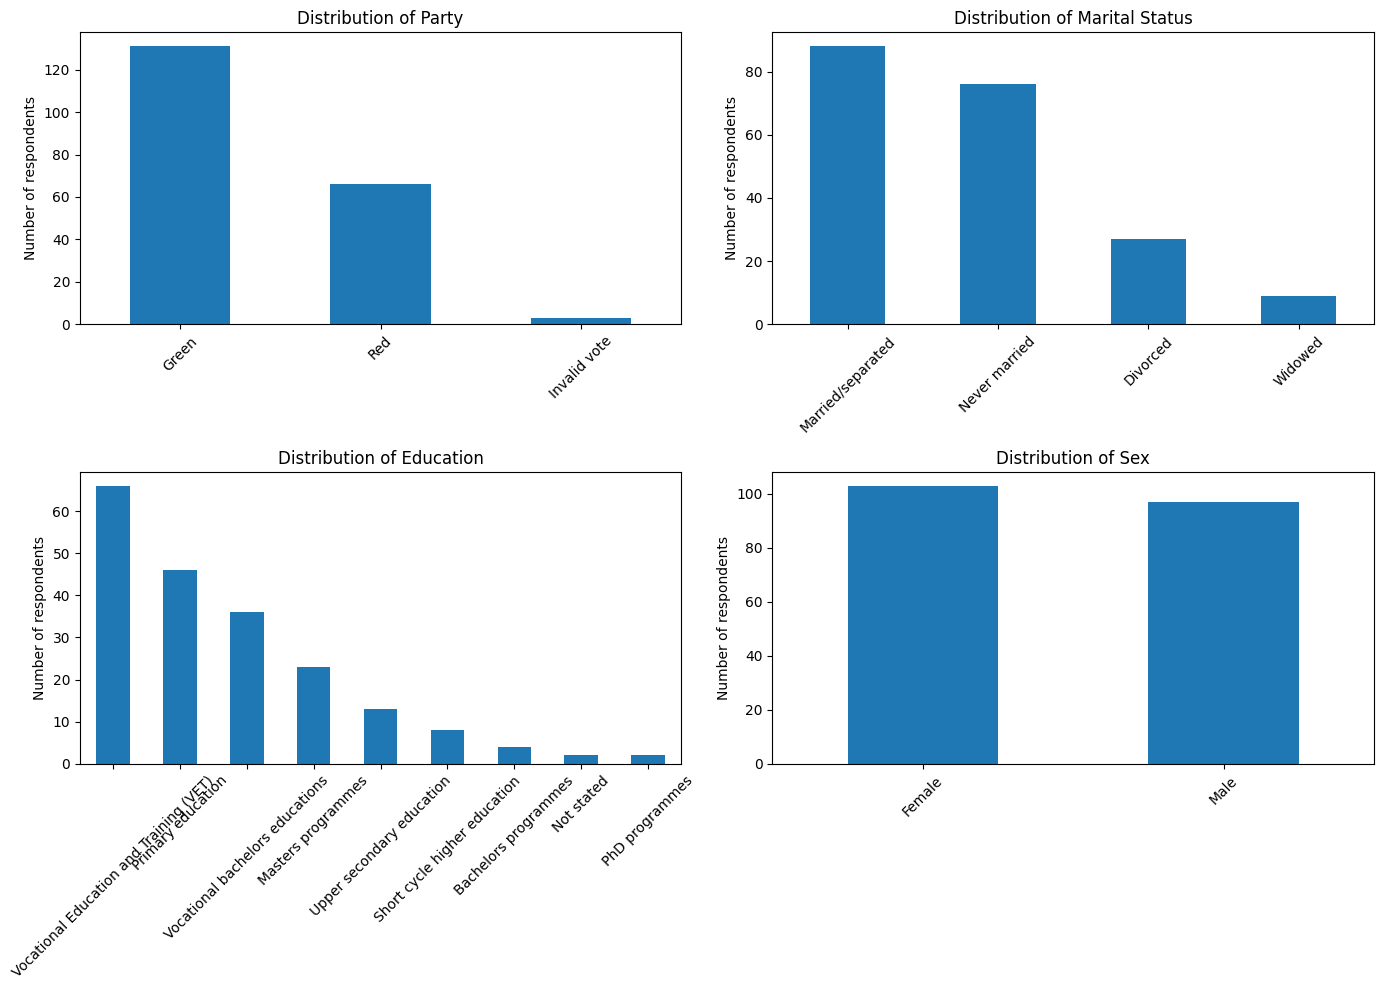

In [21]:
columns = ["party", "marital_status", "education", "sex"]

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for ax, col in zip(axes.flatten(), columns):
    counts = private_data[col].value_counts(dropna=False)

    counts.plot(kind="bar", ax=ax)

    ax.set_title(f"Distribution of {col.replace('_', ' ').title()}")
    ax.set_xlabel("")
    ax.set_ylabel("Number of respondents")
    ax.tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

In [22]:
print("Duplicate rows:", private_data.duplicated().sum())

Duplicate rows: 0


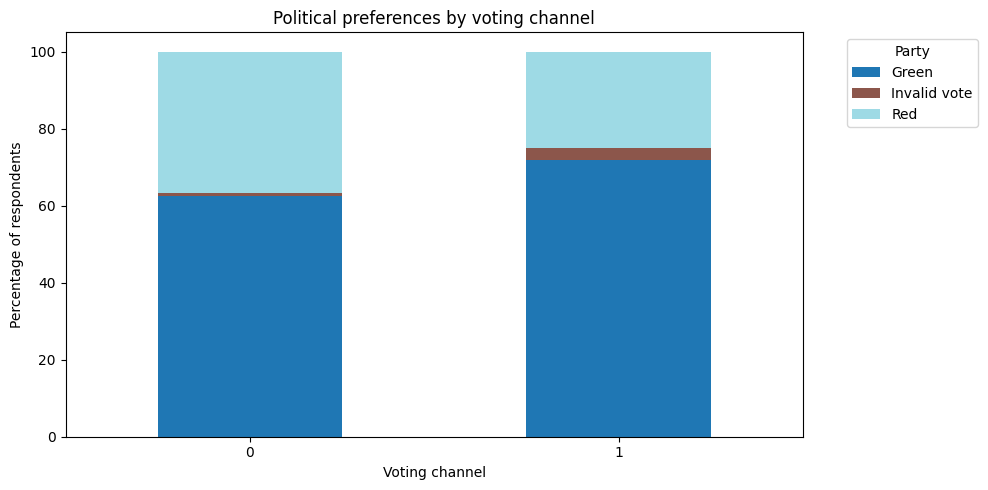

In [23]:
# Political preferences by voting channel

# Replace 'evote' with the actual column name
cross_tab = pd.crosstab(
    private_data["evote"],
    private_data["party"],
    normalize="index"
) * 100

cross_tab.plot(
    kind="bar",
    stacked=True,
    figsize=(10, 5),
    colormap="tab20"
)

plt.title("Political preferences by voting channel")
plt.xlabel("Voting channel")
plt.ylabel("Percentage of respondents")
plt.legend(title="Party", bbox_to_anchor=(1.05, 1))
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

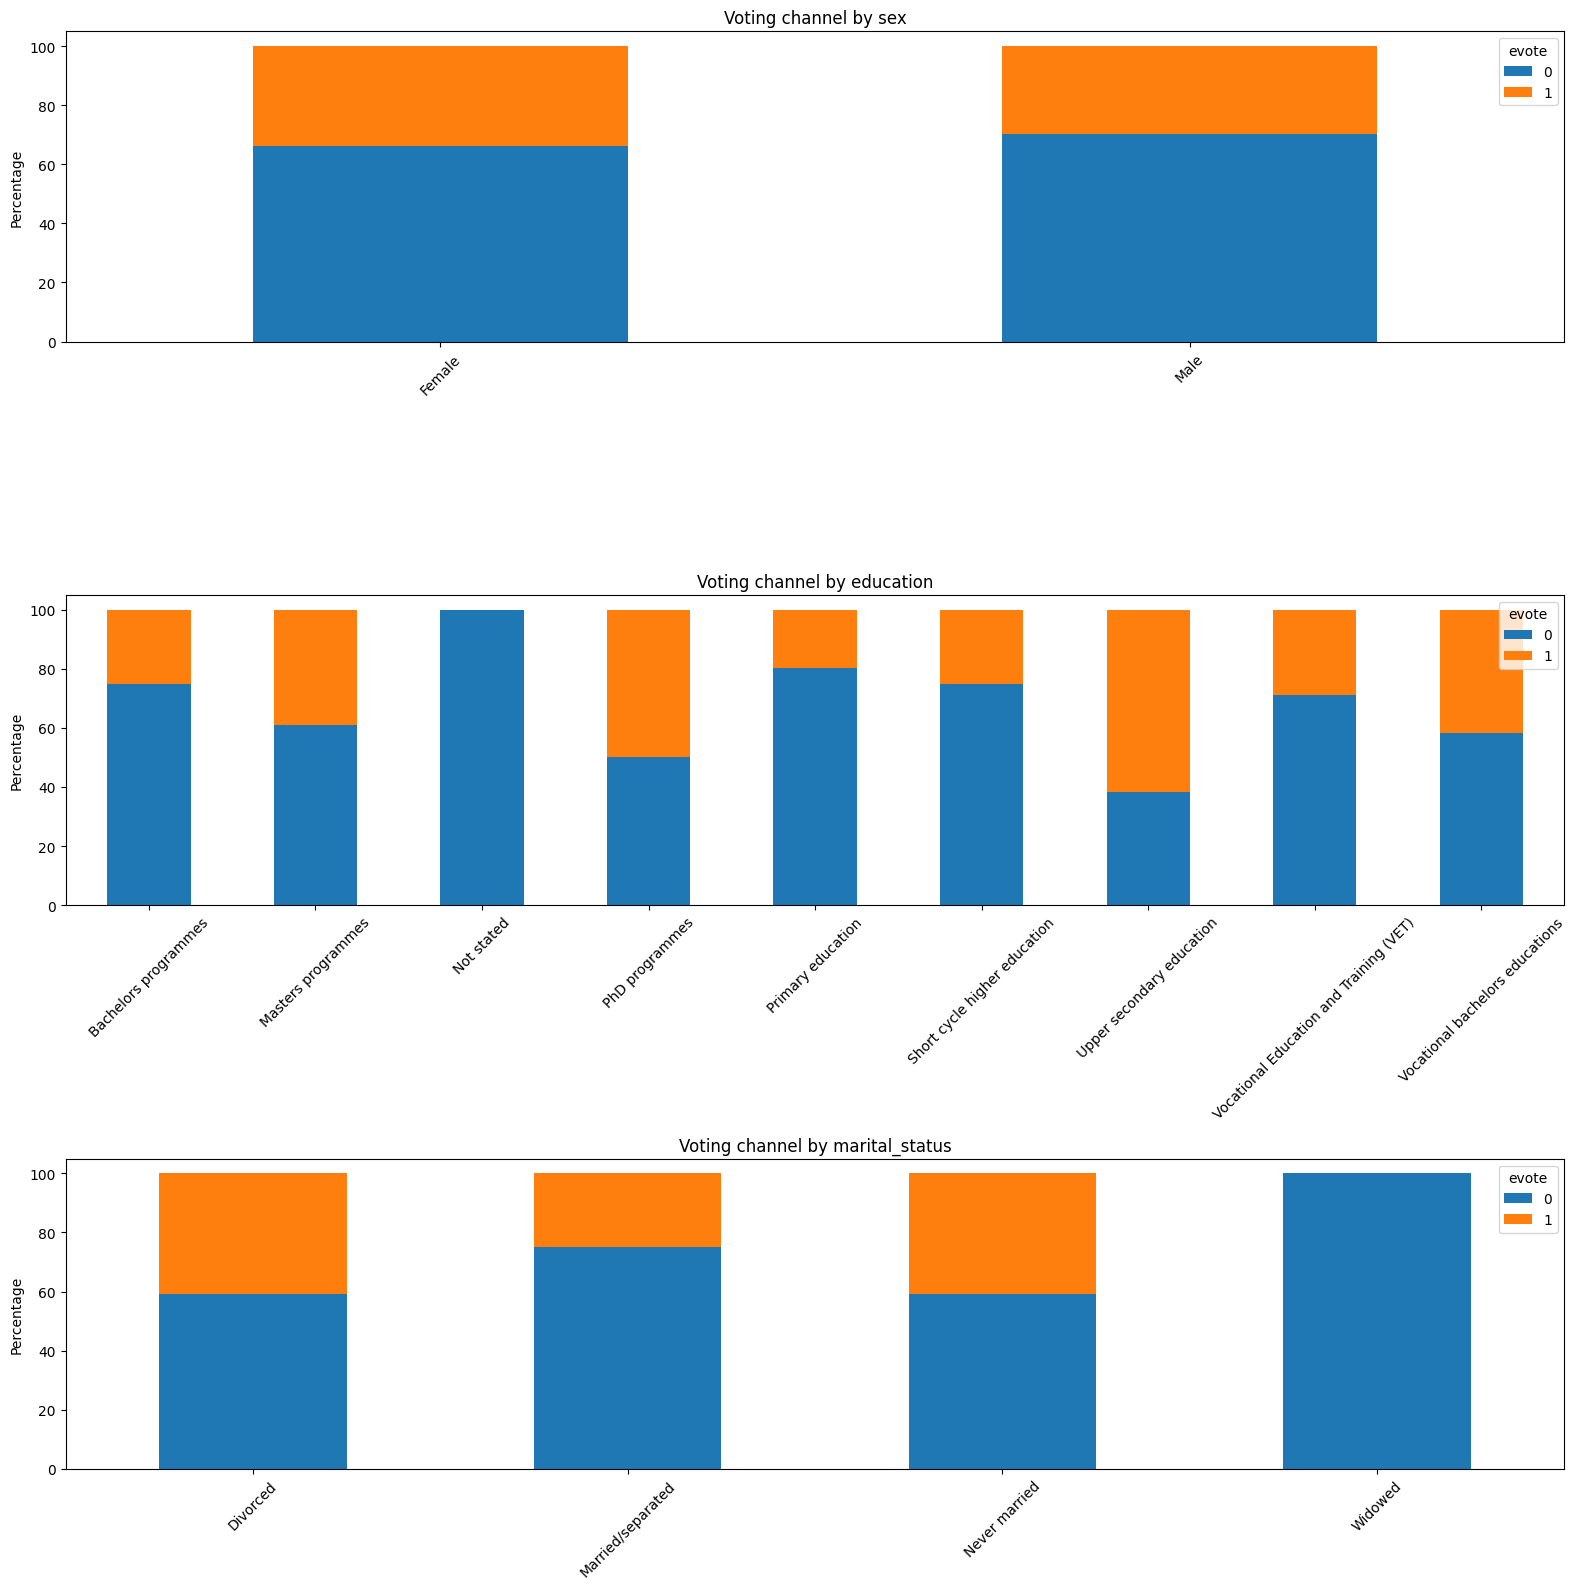

In [24]:
# Demographics by voting channel

demographics = ["sex", "education", "marital_status"]

fig, axes = plt.subplots(3, 1, figsize=(16, 16))

for ax, col in zip(axes, demographics):
    table = pd.crosstab(
        private_data[col],
        private_data["evote"],
        normalize="index"
    ) * 100

    table.plot(kind="bar", stacked=True, ax=ax)

    ax.set_title(f"Voting channel by {col}")
    ax.set_xlabel("")
    ax.set_ylabel("Percentage")
    ax.tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

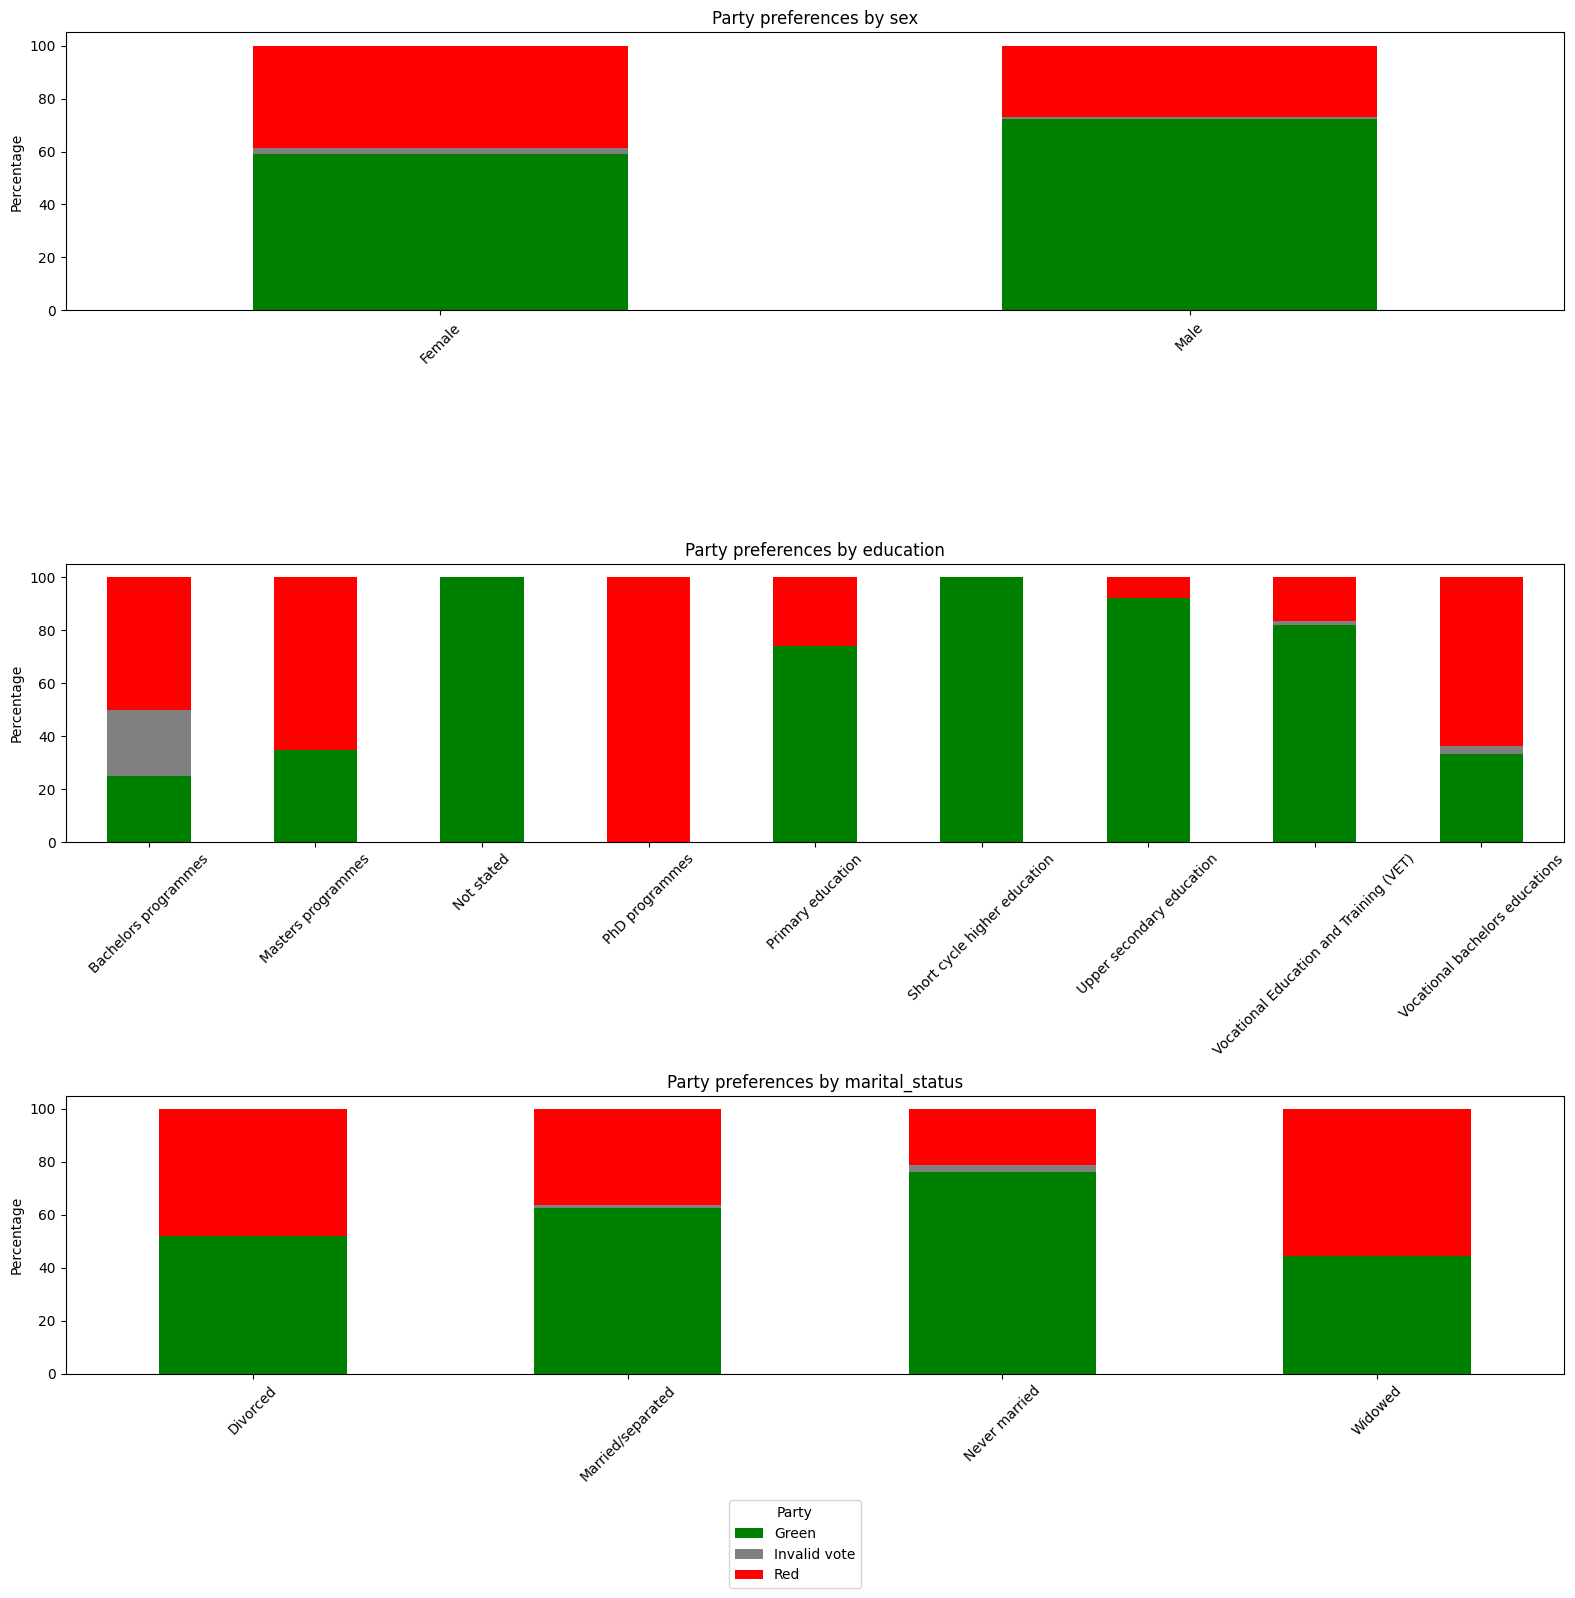

In [25]:
# Political preferences by demographics

demographics = ["sex", "education", "marital_status"]

# Define party colors
party_colors = {
    "Red": "red",
    "Green": "green",
    "Blue": "blue",
    "Yellow": "gold",
}

fig, axes = plt.subplots(3, 1, figsize=(16, 16))

for ax, col in zip(axes, demographics):
    table = pd.crosstab(
        private_data[col],
        private_data["party"],
        normalize="index"
    ) * 100

    # Match colors to party names
    colors = [
        party_colors.get(party, "gray")
        for party in table.columns
    ]

    table.plot(
        kind="bar",
        stacked=True,
        ax=ax,
        color=colors,
        legend=False
    )

    ax.set_title(f"Party preferences by {col}")
    ax.set_xlabel("")
    ax.set_ylabel("Percentage")
    ax.tick_params(axis="x", rotation=45)

handles, labels = axes[0].get_legend_handles_labels()

fig.legend(
    handles, labels,
    title="Party",
    loc="lower center",
    bbox_to_anchor=(0.5, 0)
)

plt.tight_layout(rect=[0, 0.06, 1, 1])
plt.show()

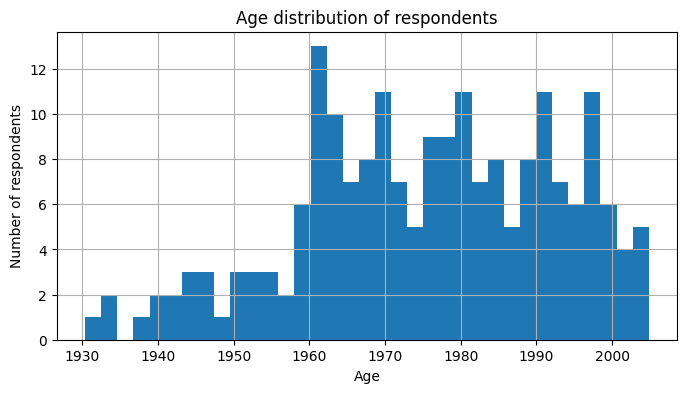

In [26]:
# Age distributions

private_data["dob"].hist(bins=35, figsize=(8, 4))

plt.title("Age distribution of respondents")
plt.xlabel("Age")
plt.ylabel("Number of respondents")
plt.show()

dob      datetime64[ns]
age               int64
evote             int64
dtype: object


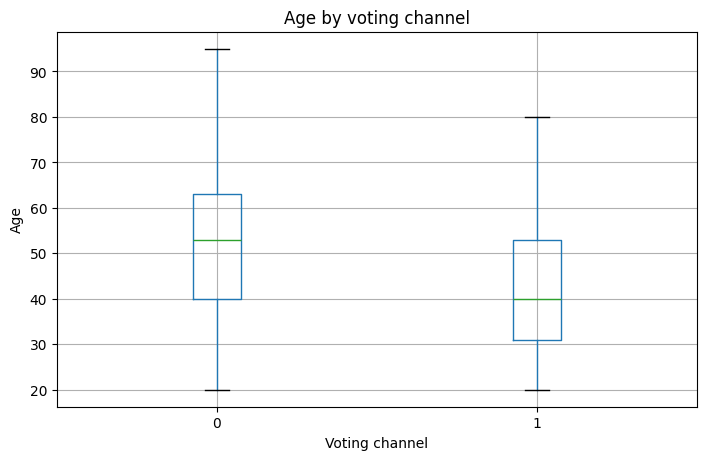

In [27]:
# Ensure dob is datetime
private_data["dob"] = pd.to_datetime(private_data["dob"])

# Calculate age at the survey date
survey_date = pd.Timestamp("2025-07-01")

private_data["age"] = (
    survey_date.year - private_data["dob"].dt.year
    - (
        (private_data["dob"].dt.month > survey_date.month)
        | (
            (private_data["dob"].dt.month == survey_date.month)
            & (private_data["dob"].dt.day > survey_date.day)
        )
    ).astype(int)
)

# Check types
print(private_data[["dob", "age", "evote"]].dtypes)

# Plot
private_data.boxplot(
    column="age",
    by="evote",
    figsize=(8, 5)
)

plt.title("Age by voting channel")
plt.suptitle("")
plt.xlabel("Voting channel")
plt.ylabel("Age")
plt.show()

In [28]:
# Compare the survey sample with the population register

print("Survey columns:")
print(private_data.columns.tolist())

print("\nPopulation register columns:")
print(public_register.columns.tolist())

display(public_register.head())

Survey columns:
['name', 'sex', 'evote', 'dob', 'zip', 'education', 'citizenship', 'marital_status', 'party', 'age']

Population register columns:
['name', 'sex', 'dob', 'zip', 'citizenship', 'marital_status', 'last_voted']


,name,sex,dob,zip,citizenship,marital_status,last_voted
0,"al-El-Sayed, Naadir",Male,2000-03-21,2200,Denmark,Never married,2
1,"Willingham, Daravion",Male,2001-01-26,2200,Denmark,Never married,2
2,"Manchego, Alisa",Female,2003-04-07,2100,Denmark,Never married,1
3,"Gildon, Brittany",Female,2004-12-28,2400,Denmark,Never married,1
4,"Ruybal, Morgan",Female,2000-09-04,2300,Denmark,Never married,1


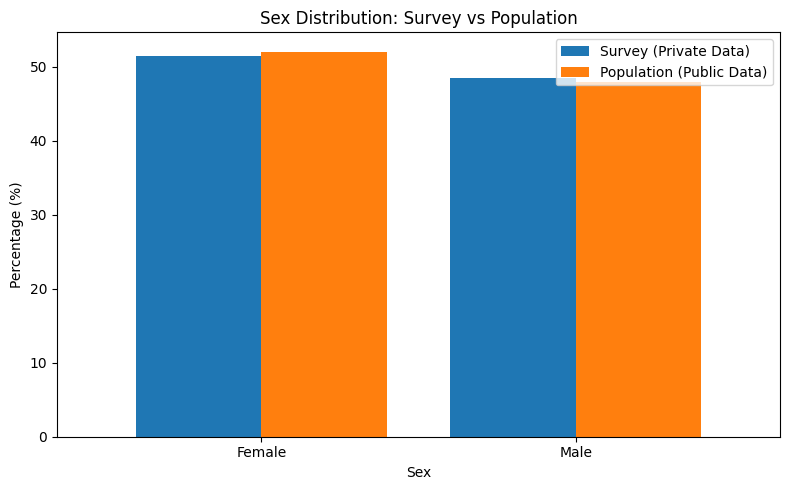

In [29]:
# Compare categorical distributions

survey_dist = private_data["sex"].value_counts(normalize=True) * 100
population_dist = public_register["sex"].value_counts(normalize=True) * 100

comparison = pd.DataFrame({
    "Survey (Private Data)": survey_dist,
    "Population (Public Data)": population_dist
}).fillna(0)

ax = comparison.plot(
    kind="bar",
    figsize=(8, 5),
    width=0.8
)

ax.set_title("Sex Distribution: Survey vs Population")
ax.set_xlabel("Sex")
ax.set_ylabel("Percentage (%)")
ax.tick_params(axis="x", rotation=0)
ax.legend()

plt.tight_layout()
plt.show()

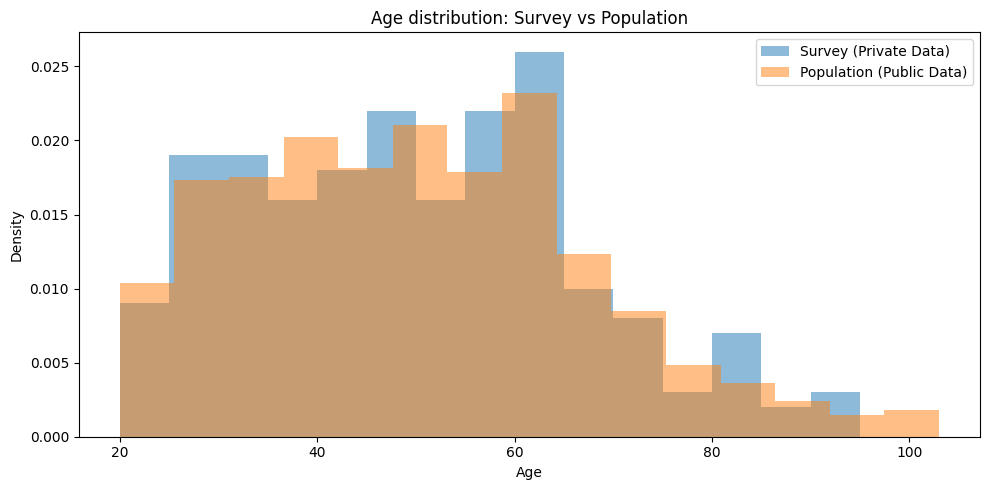

In [30]:
# Compare age distributions

survey_date = pd.Timestamp("2025-07-01")

public_register["dob"] = pd.to_datetime(public_register["dob"])

public_register["age"] = (
    survey_date.year - public_register["dob"].dt.year
    - (
        (public_register["dob"].dt.month > survey_date.month)
        | (
            (public_register["dob"].dt.month == survey_date.month)
            & (public_register["dob"].dt.day > survey_date.day)
        )
    )
)

# Compare distributions
plt.figure(figsize=(10, 5))

plt.hist(
    private_data["age"].dropna(),
    bins=15,
    density=True,
    alpha=0.5,
    label="Survey (Private Data)"
)

plt.hist(
    public_register["age"].dropna(),
    bins=15,
    density=True,
    alpha=0.5,
    label="Population (Public Data)"
)

plt.title("Age distribution: Survey vs Population")
plt.xlabel("Age")
plt.ylabel("Density")
plt.legend()
plt.tight_layout()
plt.show()

In [31]:
# Quantify the differences

for col in demographics:

    survey_dist = private_data[col].value_counts(normalize=True) * 100
    population_dist = public_register[col].value_counts(normalize=True) * 100

    comparison = pd.DataFrame({
        "Survey (Private Data)": survey_dist,
        "Population (Public Data)": population_dist
    }).fillna(0)

    comparison["Difference (pp)"] = (
        comparison["Survey (Private Data)"] - comparison["Population (Public Data)"]
    )

    print(f"\n{col.upper()}")
    display(comparison.round(2))


SEX


,Survey (Private Data),Population (Public Data),Difference (pp)
sex,,,
Female,51.5,52.07,-0.57
Male,48.5,47.93,0.57


KeyError: 'education'

# Step 1


## A. Survey Political Preferences vs. Election Results

**Question:** Is there a significant difference between the political preferences as expressed in the survey and the election results for both electronic and polling station votes?

### Hypotheses

For each voting channel, we define:

- $H_0$: The distribution of political preferences in the survey matches the published election results for that voting channel.
- $H_1$: The distribution of political preferences in the survey differs from the published election results for that voting channel.

### Method: Chi-square Goodness-of-Fit Test

We use a chi-square goodness-of-fit test to determine whether the observed distribution of political preferences in the survey differs significantly from the distribution expected based on the official election results.

The test statistic is:

$$
\chi^2 = \sum_{i=1}^{k} \frac{(O_i-E_i)^2}{E_i}
$$

where:

- $O_i$ is the observed number of survey respondents supporting party $i$.
- $E_i$ is the expected number of respondents supporting party $i$, based on the published election results.
- $k$ is the number of political parties.

The expected frequency for each party is calculated as:

$$
E_i = N \cdot p_i
$$

where $N$ is the number of survey respondents in the voting channel and $p_i$ is the proportion of votes received by party $i$ in the official election results for that channel.

We then compare the expected counts with the observed survey counts.

### Statistical Significance

We use a significance level of:

$$
\alpha = 0.05
$$

The degrees of freedom are:

$$
df = k - 1
$$

provided the party proportions are specified independently from the survey data.

- If $p < 0.05$, we reject $H_0$, indicating a statistically significant difference.
- If $p \geq 0.05$, we fail to reject $H_0$, indicating insufficient evidence of a difference.

The test is conducted separately for electronic votes and polling-station votes.

### Assumptions

The chi-square approximation requires sufficiently large expected cell counts. We will inspect these counts before interpreting the results. We also assume that survey observations are independent and that the published election proportions provide an appropriate reference distribution.


In [ ]:
print("Election results:")
display(public_results)

print("\nColumn names:")
print(public_results.columns.tolist())

print("\nVoting channels in survey (Private Data):")
display(private_data["evote"].value_counts(dropna=False))

print("\nPolitical preferences in survey (Private Data):")
display(private_data["party"].value_counts(dropna=False))

Election results:


,Unnamed: 0,Red,Green,Invalid ballots,Total
0,Polling station: ZIP 2100,30,72,4,106
1,Polling station: ZIP 2200,49,99,3,151
2,Polling station: ZIP 2300,83,81,1,165
3,Polling station: ZIP 2400,95,153,5,253
4,E-votes,123,238,10,371
5,Total,380,643,23,1046



Column names:
['Unnamed: 0', 'Red', 'Green', 'Invalid ballots', 'Total']

Voting channels in survey (Private Data):


evote
0    136
1     64
Name: count, dtype: int64


Political preferences in survey (Private Data):


party
Green           131
Red              66
Invalid vote      3
Name: count, dtype: int64

In [45]:
party_col = "party"
online_col = "evotes"
paper_col = "polling_station_votes"


# Remove rows with Invalid votes 
valid_data = private_data[
    private_data["party"].isin(["Red", "Green"])
].copy()

print(valid_data["party"].value_counts())

party
Green    131
Red       66
Name: count, dtype: int64


In [46]:
# Separate electronic and polling-station results
online_results = public_results[
    public_results["Unnamed: 0"] == "E-votes"
]

paper_results = public_results[
    public_results["Unnamed: 0"].str.startswith("Polling station")
]

# Sum votes for each party
online_votes = online_results[["Red", "Green"]].sum()
paper_votes = paper_results[["Red", "Green"]].sum()

# Calculate proportions (excluding invalid ballots)
online_proportions = online_votes / online_votes.sum()
paper_proportions = paper_votes / paper_votes.sum()

print("Electronic voting:")
display(online_proportions)

print("Polling-station voting:")
display(paper_proportions)

Electronic voting:


Red      0.34072
Green    0.65928
dtype: float64

Polling-station voting:


Red      0.388218
Green    0.611782
dtype: float64

In [47]:
# Perform the chi-square goodness-of-fit tests

results_A = []

for channel, proportions in [
    (True, online_proportions),
    (False, paper_proportions)
]:
    channel_name = "Electronic" if channel else "Polling station"

    # Observed party preferences in survey
    observed = (
        valid_data.loc[
            valid_data["evote"] == channel, "party"
        ]
        .value_counts()
        .reindex(["Red", "Green"], fill_value=0)
    )

    # Expected counts based on official results
    expected = proportions.reindex(["Red", "Green"]) * observed.sum()

    # Chi-square goodness-of-fit test
    chi2, p = chisquare(
        f_obs=observed,
        f_exp=expected
    )

    print(f"\n{channel_name} voting")
    display(pd.DataFrame({
        "Observed": observed,
        "Expected": expected.round(2),
        "Official proportion (%)": (proportions * 100).round(2)
    }))

    results_A.append({
        "Channel": channel_name,
        "N": observed.sum(),
        "Chi-square": chi2,
        "df": 1,
        "p-value": p,
        "Min expected count": expected.min(),
        "Significant (p < 0.05)": p < 0.05
    })

results_A = pd.DataFrame(results_A)
display(results_A.round(4))


Electronic voting


,Observed,Expected,Official proportion (%)
Red,16,21.12,34.07
Green,46,40.88,65.93



Polling station voting


,Observed,Expected,Official proportion (%)
Red,50,52.41,38.82
Green,85,82.59,61.18


,Channel,N,Chi-square,df,p-value,Min expected count,Significant (p < 0.05)
0,Electronic,62,1.8857,1,0.1697,21.1247,False
1,Polling station,135,0.1811,1,0.6705,52.4094,False


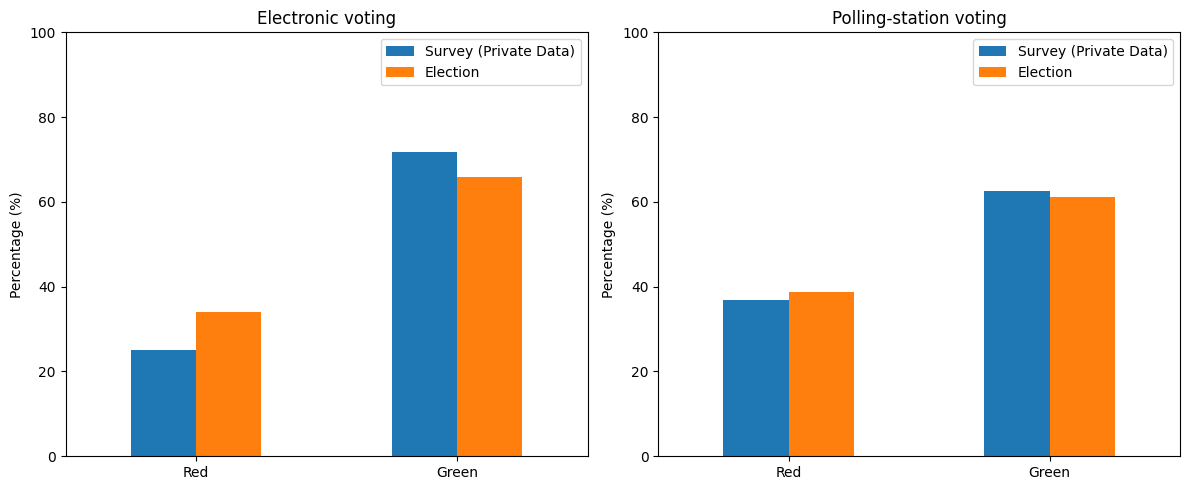

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, channel, proportions, title in [
    (axes[0], True, online_proportions, "Electronic voting"),
    (axes[1], False, paper_proportions, "Polling-station voting")
]:
    observed = (
        private_data.loc[
            private_data["evote"] == channel, "party"
        ]
        .value_counts(normalize=True)
        .reindex(["Red", "Green"], fill_value=0)
        * 100
    )

    expected = proportions.reindex(["Red", "Green"]) * 100

    comparison = pd.DataFrame({
        "Survey (Private Data)": observed,
        "Election": expected
    })

    comparison.plot(kind="bar", ax=ax)

    ax.set_title(title)
    ax.set_ylabel("Percentage (%)")
    ax.set_xlabel("")
    ax.set_ylim(0, 100)
    ax.tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()


### Results and Interpretation

A chi-square goodness-of-fit test was conducted separately for electronic and polling-station voters to determine whether political preferences expressed in the survey differed significantly from the published election results.

For electronic voting ($N=62$), no statistically significant difference was found between the survey and the official election results:

$$
\chi^2(1)=1.8857,\quad p=0.1697
$$

Similarly, for polling-station voting ($N=135$), the difference was not statistically significant:

$$
\chi^2(1)=0.1811,\quad p=0.6705
$$

**Conclusion:** At a significance level of $\alpha=0.05$, we fail to reject the null hypothesis for both voting channels. The analyses provide insufficient evidence that political preferences expressed in the survey differ from the published election results.

However, a non-significant result does not establish that the distributions are identical. In particular, the relatively small electronic-voting sample ($N=62$) limits the statistical power to detect smaller discrepancies.



## B. Political Preferences and Demographic Attributes

**Research question:** Is there a statistically significant association between political preferences and demographic attributes (age, sex, education, and marital status)?

### Hypotheses

For each demographic variable, we define:

- $H_0$: Political preference is independent of the demographic attribute.
- $H_1$: Political preference is associated with the demographic attribute.

### Method: Chi-square Test of Independence

We use Pearson's chi-square test of independence to determine whether political preferences differ significantly across demographic groups.

The test statistic is:

$$
\chi^2 = \sum_{i=1}^{r}\sum_{j=1}^{c}
\frac{(O_{ij}-E_{ij})^2}{E_{ij}}
$$

where:

- $O_{ij}$ is the observed frequency for demographic category $i$ and political party $j$.
- $E_{ij}$ is the expected frequency under the assumption of independence.
- $r$ and $c$ are the numbers of demographic categories and political parties.

Expected frequencies are calculated as:

$$
E_{ij} = \frac{n_{i\cdot}n_{\cdot j}}{N}
$$

The degrees of freedom are:

$$
df=(r-1)(c-1)
$$

### Effect Size: Cramér's V

To measure the strength of each association, we calculate:

$$
V = \sqrt{\frac{\chi^2}{N\min(r-1,c-1)}}
$$

Cramér's V ranges from 0 (no association) to 1 (stronger association).

### Statistical Significance

We use a significance level of $\alpha=0.05$.

Since four demographic variables are tested, we apply Holm's correction to control the family-wise error rate.

We also examine expected cell frequencies to assess whether the chi-square approximation is appropriate.


In [48]:
# Calculate age at survey date
survey_date = pd.Timestamp("2025-07-01")
valid_data["dob"] = pd.to_datetime(valid_data["dob"])

valid_data["age"] = (
    survey_date.year - valid_data["dob"].dt.year
    - (
        (valid_data["dob"].dt.month > survey_date.month)
        | (
            (valid_data["dob"].dt.month == survey_date.month)
            & (valid_data["dob"].dt.day > survey_date.day)
        )
    )
)

# Generalise age
valid_data["age_group"] = pd.cut(
    valid_data["age"],
    bins=[0, 29, 39, 49, 59, 120],
    labels=["0-29", "30-39", "40-49", "50-59", "60+"],
    include_lowest=True
)

In [49]:
demographics = ["sex", "education", "marital_status", "age_group"]

results_B = []

for col in demographics:

    table = pd.crosstab(
        valid_data[col],
        valid_data["party"]
    )

    chi2, p, dof, expected = chi2_contingency(
        table,
        correction=False
    )

    n = table.to_numpy().sum()
    r, c = table.shape

    cramers_v = np.sqrt(
        chi2 / (n * min(r - 1, c - 1))
    )

    results_B.append({
        "Variable": col,
        "N": n,
        "Chi-square": chi2,
        "df": dof,
        "p-value": p,
        "Cramér's V": cramers_v,
        "Min expected": expected.min(),
        "Cells < 5 (%)": (expected < 5).mean() * 100
    })

    print(f"\n{col.upper()}")
    display(table)

results_B = pd.DataFrame(results_B)

display(results_B.round(4))


SEX


party,Green,Red
sex,,
Female,61,40
Male,70,26



EDUCATION


party,Green,Red
education,,
Bachelors programmes,1,2
Masters programmes,8,15
Not stated,2,0
PhD programmes,0,2
Primary education,34,12
Short cycle higher education,8,0
Upper secondary education,12,1
Vocational Education and Training (VET),54,11
Vocational bachelors educations,12,23



MARITAL_STATUS


party,Green,Red
marital_status,,
Divorced,14,13
Married/separated,55,32
Never married,58,16
Widowed,4,5



AGE_GROUP


party,Green,Red
age_group,,
0-29,27,0
30-39,27,7
40-49,25,15
50-59,17,20
60+,35,24


,Variable,N,Chi-square,df,p-value,Cramér's V,Min expected,Cells < 5 (%)
0,sex,197,3.4633,1,0.0627,0.1326,32.1624,0.0000
1,education,197,50.2167,8,0.0000,0.5049,0.6701,44.4444
2,marital_status,197,9.6728,3,0.0216,0.2216,3.0152,12.5000
3,age_group,197,24.8134,4,0.0001,0.3549,9.0457,0.0000


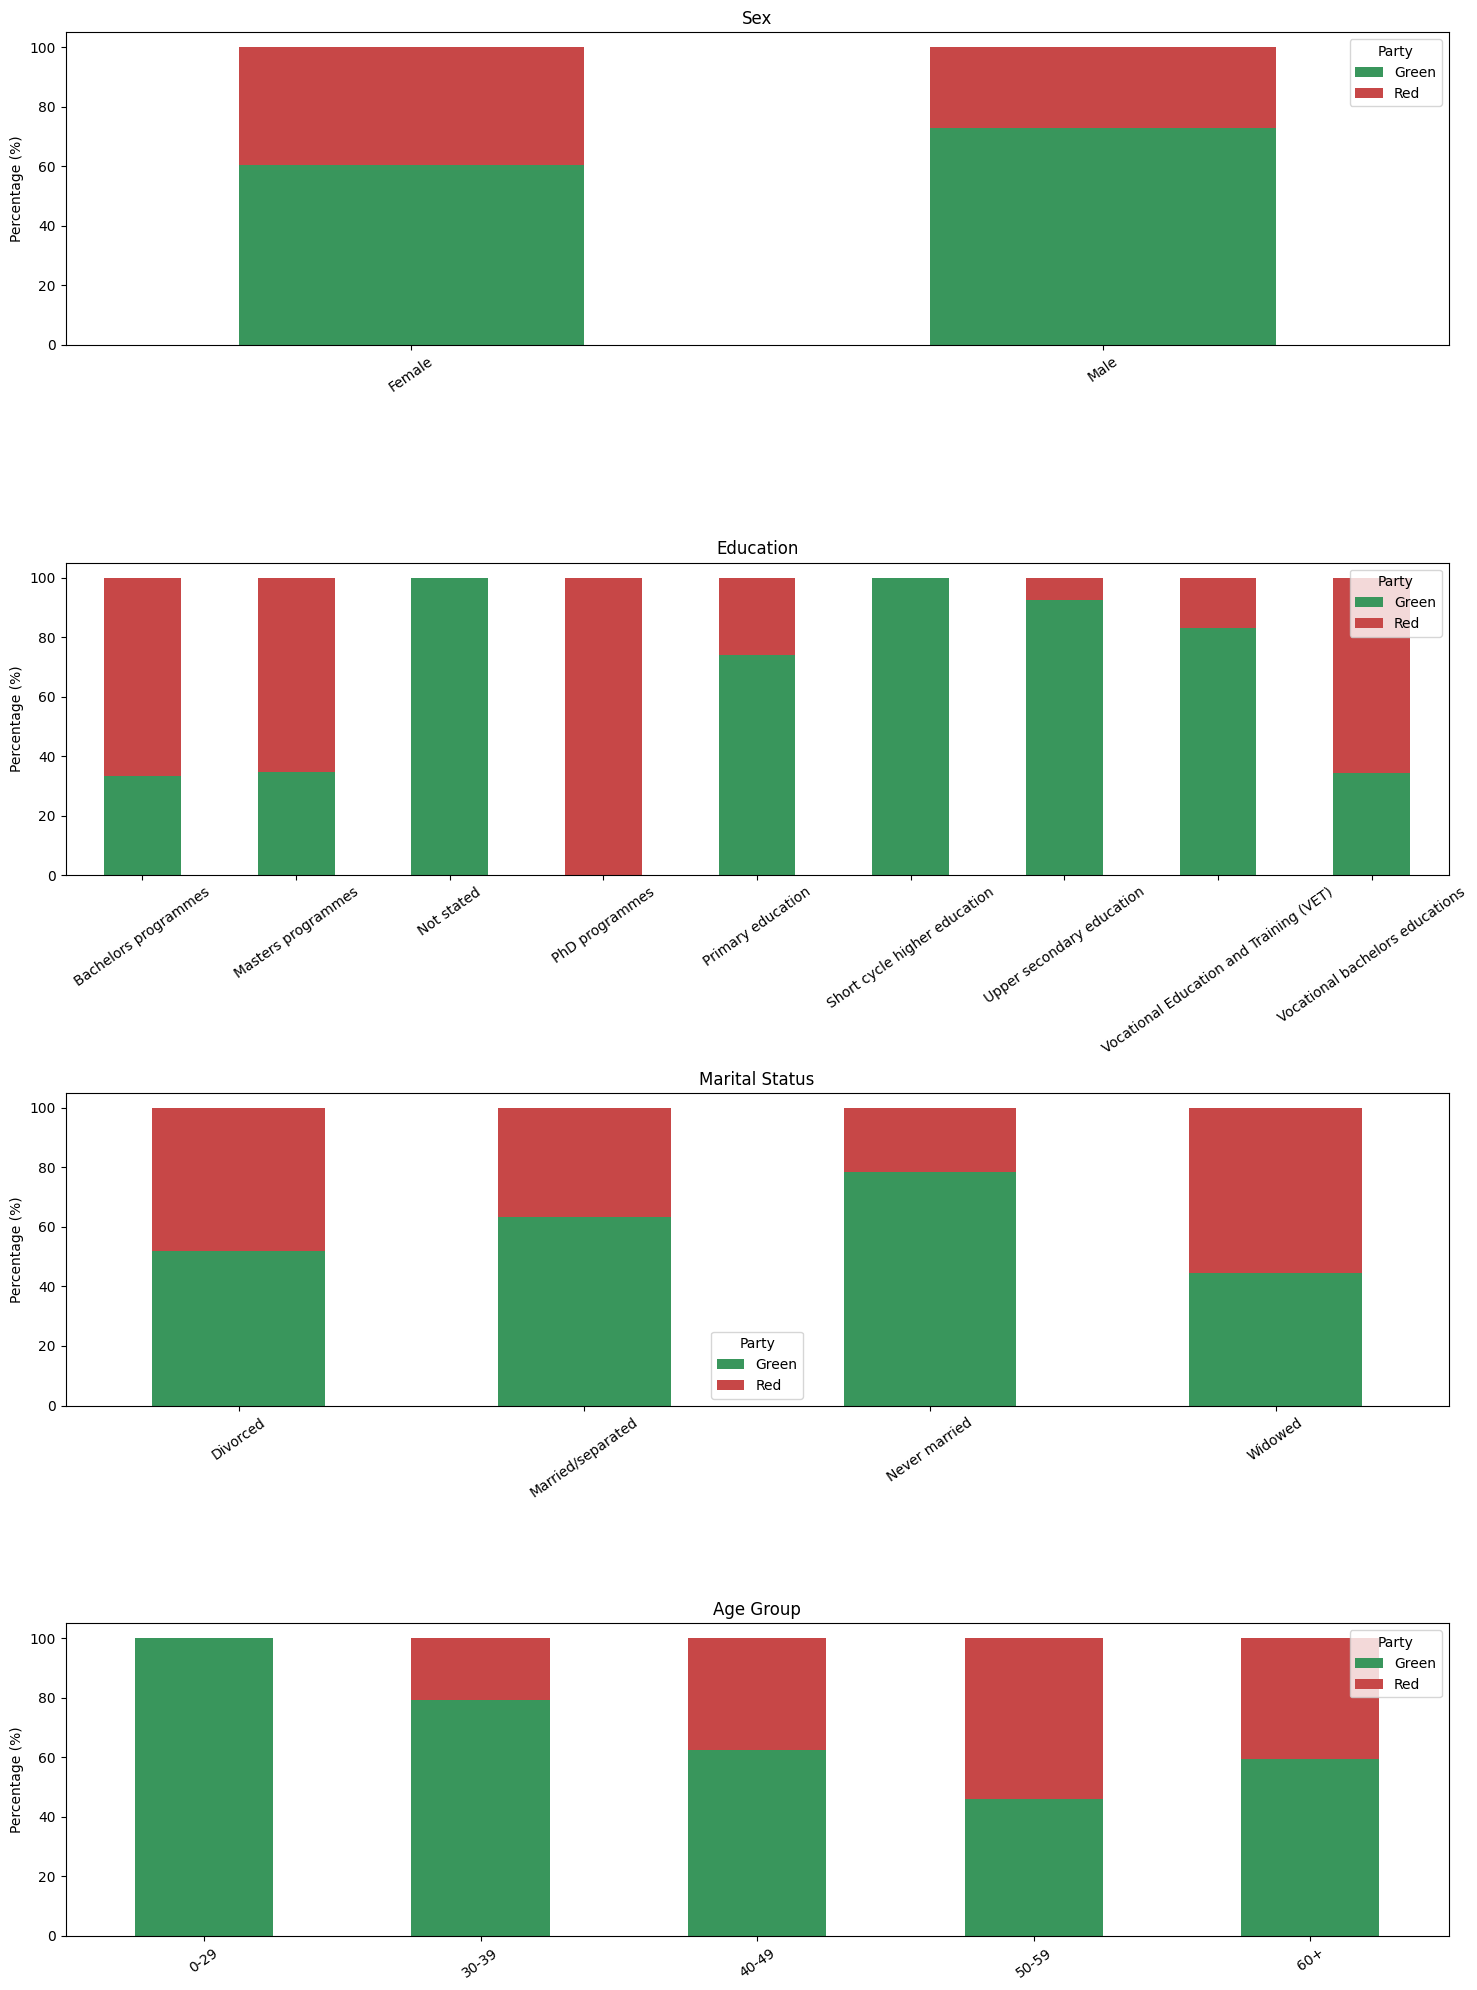

In [56]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(4, 1, figsize=(15, 20))

for ax, col in zip(axes.flat, demographics):
    table = pd.crosstab(
        valid_data[col],
        valid_data["party"],
        normalize="index"
    ) * 100

    table.plot(
        kind="bar",
        stacked=True,
        ax=ax,
        color=["#39965C", "#C74747"]
    )

    ax.set_title(col.replace("_", " ").title())
    ax.set_ylabel("Percentage (%)")
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=35)
    ax.legend(title="Party")

plt.tight_layout()
plt.show()


### Preliminary Results and Interpretation

The analysis included 197 respondents who expressed a valid political preference (Red or Green). Pearson's chi-square tests of independence were conducted to examine associations between political preference and four demographic attributes.

No statistically significant association was found for sex ($\chi^2(1)=3.4633$, $p=0.0627$, $V=0.133$).

Education showed the strongest observed association ($\chi^2(8)=50.2167$, $p<0.0001$, $V=0.505$), followed by age group ($\chi^2(4)=24.8134$, $p\approx0.0001$, $V=0.355$).

Marital status also showed a nominally significant association ($\chi^2(3)=9.6728$, $p=0.0216$, $V=0.222$).



## C. Voting Channel and Demographic Attributes

**Research question:** Is there a statistically significant association between voters' choice of voting channel (electronic or polling-station voting) and their demographic attributes (sex, education, marital status, and age group)?

### Hypotheses

For each demographic attribute:

- $H_0$: Voting channel is independent of the demographic attribute.
- $H_1$: Voting channel is associated with the demographic attribute.

### Method: Chi-square Test of Independence

We use Pearson's chi-square test of independence to investigate whether the distribution of voting channels differs across demographic groups.

The test statistic is:

$$
\chi^2 = \sum_{i=1}^{r}\sum_{j=1}^{c}
\frac{(O_{ij}-E_{ij})^2}{E_{ij}}
$$

where $O_{ij}$ is the observed frequency and $E_{ij}$ is the expected frequency under independence:

$$
E_{ij} = \frac{n_{i\cdot}n_{\cdot j}}{N}
$$

The degrees of freedom are:

$$
df=(r-1)(c-1)
$$

### Effect Size: Cramér's V

We calculate Cramér's V to measure the strength of each association:

$$
V = \sqrt{\frac{\chi^2}{N\min(r-1,c-1)}}
$$

### Statistical Significance

We use a significance level of $\alpha=0.05$.

Since four demographic variables are tested, Holm's correction is applied to control the family-wise error rate.

For contingency tables with sparse expected frequencies, Monte Carlo p-values are used instead of relying on the asymptotic chi-square approximation.


In [58]:
# Keep respondents with a valid voting channel
channel_data = private_data[
    private_data["evote"].isin([0, 1])
].copy()

print(channel_data["evote"].value_counts())

# Optional readable labels
channel_data["voting_channel"] = channel_data["evote"].map({
    0: "Polling station",
    1: "Electronic"
})

evote
0    136
1     64
Name: count, dtype: int64


In [59]:
demographics = ["sex", "education", "marital_status", "age_group"]

results_C = []

for col in demographics:

    table = pd.crosstab(
        channel_data[col],
        channel_data["voting_channel"]
    )

    # Pearson chi-square statistic and expected frequencies
    chi2, p, dof, expected = chi2_contingency(
        table,
        correction=False
    )


    n = table.to_numpy().sum()
    r, c = table.shape

    cramers_v = np.sqrt(
        chi2 / (n * min(r - 1, c - 1))
    )

    results_C.append({
        "Variable": col,
        "N": n,
        "Chi-square": chi2,
        "df": dof,
        "p-value": p,
        "Cramér's V": cramers_v,
        "Min expected": expected.min(),
        "Cells < 5 (%)": (expected < 5).mean() * 100
    })

    print(f"\n{col.upper()}")
    display(table)

results_C = pd.DataFrame(results_C)

display(results_C.round(4))


SEX


voting_channel,Electronic,Polling station
sex,,
Female,35,68
Male,29,68



EDUCATION


voting_channel,Electronic,Polling station
education,,
Bachelors programmes,1,3
Masters programmes,9,14
Not stated,0,2
PhD programmes,1,1
Primary education,9,37
Short cycle higher education,2,6
Upper secondary education,8,5
Vocational Education and Training (VET),19,47
Vocational bachelors educations,15,21



MARITAL_STATUS


voting_channel,Electronic,Polling station
marital_status,,
Divorced,11,16
Married/separated,22,66
Never married,31,45
Widowed,0,9



AGE_GROUP


voting_channel,Electronic,Polling station
age_group,,
0-29,14,14
30-39,16,19
40-49,14,26
50-59,9,29
60+,11,48


,Variable,N,Chi-square,df,p-value,Cramér's V,Min expected,Cells < 5 (%)
0,sex,200,0.3828,1,0.5361,0.0438,31.04,0.0000
1,education,200,12.3869,8,0.1348,0.2489,0.64,44.4444
2,marital_status,200,9.8631,3,0.0198,0.2221,2.88,12.5000
3,age_group,200,13.4040,4,0.0095,0.2589,8.96,0.0000


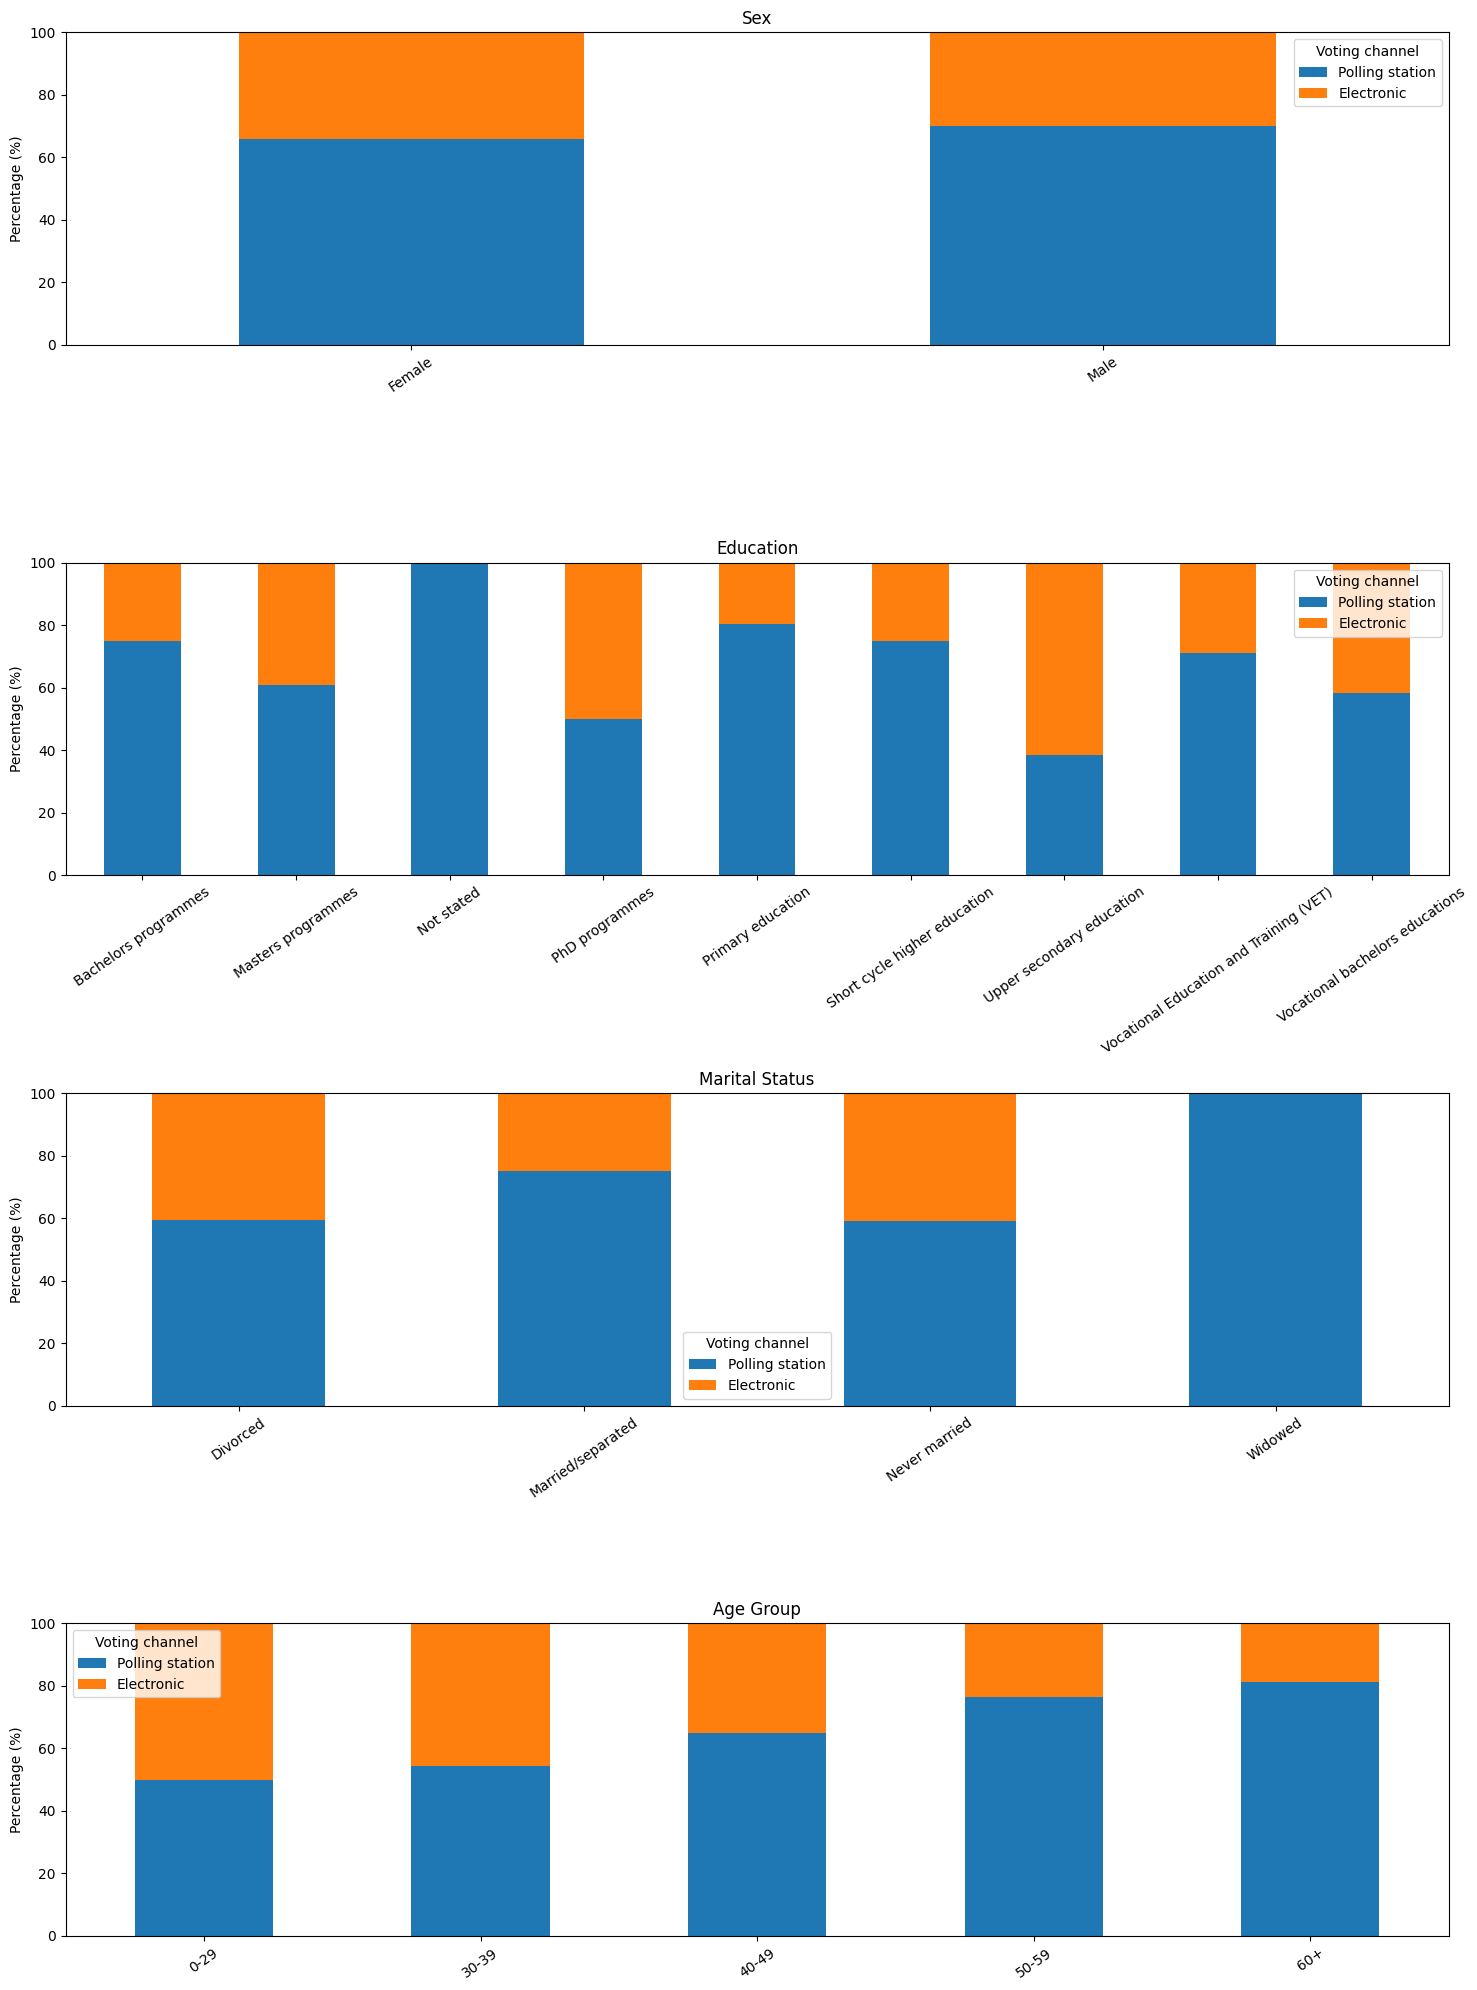

In [60]:
fig, axes = plt.subplots(4, 1, figsize=(15, 20))

for ax, col in zip(axes.flat, demographics):

    table = pd.crosstab(
        channel_data[col],
        channel_data["voting_channel"],
        normalize="index"
    ) * 100

    table = table.reindex(
        columns=["Polling station", "Electronic"],
        fill_value=0
    )

    table.plot(
        kind="bar",
        stacked=True,
        ax=ax
    )

    ax.set_title(col.replace("_", " ").title())
    ax.set_ylabel("Percentage (%)")
    ax.set_xlabel("")
    ax.set_ylim(0, 100)
    ax.tick_params(axis="x", rotation=35)
    ax.legend(title="Voting channel")

plt.tight_layout()
plt.show()


### Results and Interpretation

The analysis included all 200 survey respondents, including those who cast invalid votes, since voting-channel choice is independent of whether a valid party preference was expressed.

Pearson's chi-square tests of independence were conducted to investigate associations between voting channel and four demographic attributes.

No statistically significant association was found for **sex** ($\chi^2(1)=0.3828$, $p=0.5361$, $V=0.044$) or **education** ($\chi^2(8)=12.3869$, $p=0.1348$, $V=0.249$).

**Marital status** showed a nominally significant association ($\chi^2(3)=9.8631$, $p=0.0198$, $V=0.222$), as did **age group** ($\chi^2(4)=13.4040$, $p=0.0095$, $V=0.259$).
